In [2]:
# Simple Particle-in-field-Solver, for a single particle
# copied from evolver 2 but want to check against my analytical solution

findex = 24  #64 
q = -1

In [3]:
# Imports
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib widget
import random as ra
import sys; sys.path.append('..')
from useful_funcs import *
sys.path.append('../fmgmt')
from TristanRun import TristanRun

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 14

from scipy.optimize import root_scalar

In [4]:
# Init Conditions 

# Ez / (c B0), By / B0, deltax / c_omp, Bx / B0, deltay / c_omp, v_infl / v_A

inits = {
    2: [0.155, 0.38, 0.646, 0.2, 3.83],
    #6: [0.35, 0.25, 1.41, 0.25, 3.56],
    6: [0.4, 0.262, 0.78, 0.17, 2.2],
    8: [0.048, 1.383, 0.5, 0.558, 2.18]
}

spare_ex = 0

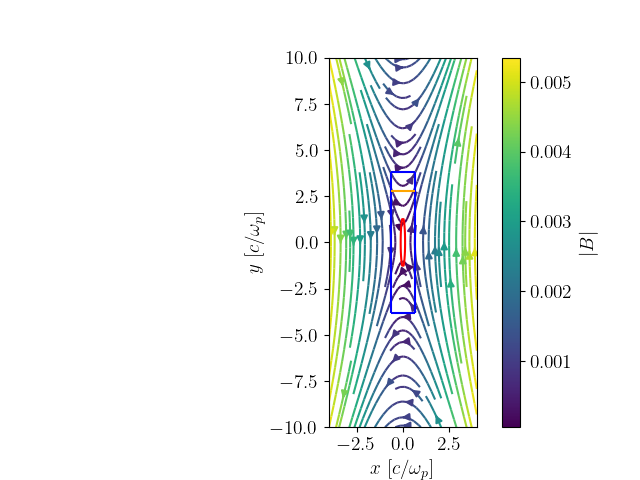

In [5]:
# Compute Quantities
run = TristanRun(findex)

cc = 0.45
c_omp = run.c_omp
sigma = run.sigma
boilerplate = run.boilerplate

init = inits[int(str(findex)[0])] #(E, By0, deltax, Bx0, deltay)


B0 = (cc ** 2 * np.sqrt(sigma) / c_omp)

Ez = init[0] * cc * B0
By0 = init[1] * B0
delta_x = init[2] * c_omp
Bx0 = init[3] * B0
delta_y = init[4] * c_omp
beta_A = np.sqrt(sigma / (sigma + 1))

gyrofreq = cc * np.sqrt(sigma) / c_omp

def Bx(y):
    return Bx0 * y / delta_y

def By(x):
    return By0 * x / delta_x 

def Ex(x):
    return 0.165 / (0.44 * c_omp) * x * cc * B0 * spare_ex

def B(vector):
    x = vector[0]; y = vector[1]; z = vector[2]

    return np.array([Bx(y), By(x), 0])

gate = Ez * delta_y / (Bx0 * beta_A)

Y, X = np.mgrid[-10:10:100j, -4:4:100j] * c_omp #do not really understand why this is flipped

Bsq = Bx(Y) ** 2 + By(X) ** 2
chi = (Bsq - Ez ** 2) / (Bsq + Ez ** 2)

plt.figure()
splot = plt.streamplot(X / c_omp, Y / c_omp, Bx(Y), By(X), color = np.sqrt(Bsq), cmap = 'viridis')
plt.colorbar(splot.lines, label = '$|B|$')
plt.contour(X / c_omp, Y / c_omp, chi, [0], colors = 'red')
plt.vlines([delta_x / c_omp, -delta_x / c_omp], - delta_y / c_omp, delta_y / c_omp, colors = 'blue')
plt.hlines([delta_y / c_omp, -delta_y / c_omp], - delta_x / c_omp, delta_x / c_omp, colors = 'blue')
plt.hlines([gate / c_omp], - delta_x / c_omp, delta_x / c_omp, colors = 'orange')
plt.gca().set_aspect(1)
plt.xlabel('$x$ [$c/\omega_{p}$]'); plt.ylabel('$y$ [$c/\omega_{p}$]')

plt.show()

In [6]:
b = Bx0 / delta_y

Delta = Ez / b
tau_E = np.sqrt(Delta / Ez)
Omega = b * Delta / cc 

epsilon = Omega * tau_E

W0 = Delta * Ez

def dydW(energy, epsilon): #yf if want exact nums
    #yf = yf / Delta
    W = energy / W0
    fudge = 0.05 #0.14
    return fudge * gate * epsilon ** (7 / 12) / (2 * W) ** 0.25 * np.exp(- 2/3 * epsilon ** 0.5 * (2 * W) ** 0.75)

def bessho(energy):
    coeff = np.sqrt(4 * b * cc ** 2 / (Ez ** 2)) 
    W = energy

    fudge = 5

    return fudge * W ** -0.25 * np.exp(-coeff * W ** 0.5)

print(f"W0 is {W0:.2e}, corresponding to gamma = {1 + W0 / (cc ** 2):.2e}")
print(f"epsilon is {epsilon:.2e}")

W0 is 1.03e-02, corresponding to gamma = 1.05e+00
epsilon is 2.26e-01


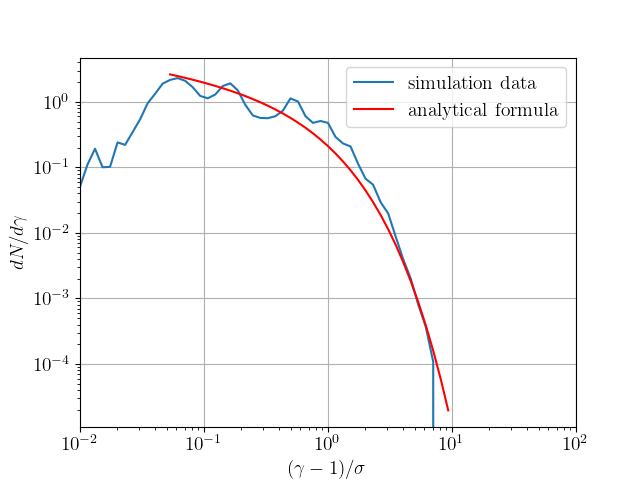

In [7]:
# fitted spectra

findex = 24

floc = TristanRun.find_folderpath(findex)

real_bin = np.load(f"{floc}/aux_files/bins.npy")
real_hist = np.load(f"{floc}/aux_files/hist.npy")

filtered_bins = real_bin[(real_bin >= 0.05) & (real_bin <= 10)]



plt.figure()
plt.loglog(real_bin, real_hist, label = 'simulation data')
#plt.loglog(bins[1:], hist, label = 'integrated solution')
#plt.loglog(bins[1:], 0.35 * juttner_synge(real_gammas, 0.15)) #0.35, 0.15 (7, 1.25)
#plt.loglog(bins[1:], dydW((bins[1:] * run.sigma) * cc ** 2, epsilon), label = 'analytical')
plt.loglog(filtered_bins, dydW((filtered_bins* run.sigma) * cc ** 2, epsilon), label = 'analytical formula', color = 'red')
#plt.loglog(filtered_bins, bessho((filtered_bins * run.sigma) * cc ** 2), label = 'analytical_b')
plt.xlabel('$(\gamma - 1) / \sigma$')
plt.ylabel("$dN / d\gamma$")
plt.legend()
plt.grid()
plt.xlim(10.0 ** np.array([-2, 2]))

save_polished_fig("analytic_fit")
plt.show()

1.139901881468883
5.025189076296055


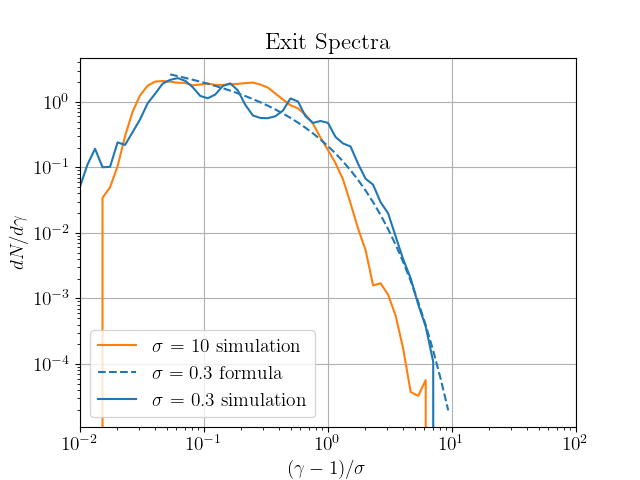

In [10]:
# Both plotted

findex = 24
fpath = TristanRun.find_folderpath(findex)

real_bin1 = np.load(f"{fpath}/aux_files/bins.npy")
real_hist1 = np.load(f"{fpath}/aux_files/hist.npy")

findex = 64
fpath = TristanRun.find_folderpath(findex)

real_bin2 = np.load(f"{fpath}/aux_files/bins.npy")
real_hist2 = np.load(f"{fpath}/aux_files/hist.npy")



plt.figure()

plt.loglog(real_bin2, real_hist2, label = '$\sigma$ = 10 simulation', color = '#ff7f0e') #orange


plt.loglog(filtered_bins, dydW((filtered_bins* run.sigma) * cc ** 2, epsilon), 
           label = '$\sigma = 0.3$ formula', color = '#1f77b4', linestyle = 'dashed')

plt.loglog(real_bin1, real_hist1, label = '$\sigma$ = 0.3 simulation', color = '#1f77b4') #blue


aspeeds = [0.48, 0.98]
sigmas = [0.3, 10]
cores = ['orange', 'blue']

for i in range(2):
    aspeed = aspeeds[i]
    sigma = sigmas[i]
    R = 0.1
    gamma = (1 - (aspeed) ** 2) ** -0.5
    print(gamma)

    #plt.axvline((gamma - 1) / sigma, color = cores[i], linestyle = '--')

plt.xlabel('$(\gamma - 1) / \sigma$')
plt.ylabel("$dN / d\gamma$")
plt.title("Exit Spectra")
plt.legend()
plt.grid()
plt.xlim(10.0 ** np.array([-2, 2]))

save_polished_fig("exit_spectra")
plt.show()